# 04. Random forest regression

We predict the final numerical grade (`course_numeric_grade`) from Moodle activity during the first 8 weeks of the semester. The model is a Random Forest (`RandomForestRegressor`). It is trained on the earlier years and tested separately on 2025 and 2026, using exactly the same prepared dataset and the same four predictors as the other models in the team.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error

RANDOM_STATE = 42

## 1. Load the shared datasets

In [4]:
train = pd.read_csv("shared_train.csv")
test = pd.read_csv("shared_test.csv")

print("train:", train.shape, " test:", test.shape)
print("train years:", sorted(train["year"].unique()))
print("test years:", sorted(test["year"].unique()))
train.head()

train: (551, 7)  test: (279, 7)
train years: [np.int64(2019), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]
test years: [np.int64(2025), np.int64(2026)]


,year,actor_id,course_numeric_grade,total_events,active_days,course_module_views,course_views
0,2019,S027cf9,72.10,132,18,20,34
1,2019,S032255,67.70,48,6,18,8
2,2019,S03a8b8,107.02,221,30,39,75
3,2019,S04cf7f,85.85,161,20,26,38
4,2019,S05f285,37.15,456,32,76,177


## 2. Select predictors and target variable

In [24]:
FEATURES = ["total_events", "active_days", "course_module_views", "course_views"]
TARGET = "course_numeric_grade"

X_train = train[FEATURES]
y_train = train[TARGET]
groups = train["year"]  # year of each training row (used later)

X_test_2025 = test.loc[test["year"] == 2025, FEATURES]
y_test_2025 = test.loc[test["year"] == 2025, TARGET]
X_test_2026 = test.loc[test["year"] == 2026, FEATURES]
y_test_2026 = test.loc[test["year"] == 2026, TARGET]

print(len(X_train), len(X_test_2025), len(X_test_2026))

551 137 142


## 3. Train a basic Random Forest

A Random Forest combines predictions from multiple decision trees. We first train a model with 100 trees and calculate its training error. Later, we will tune the model using cross-validation to reduce overfitting.

In [7]:
forest = RandomForestRegressor(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

forest.fit(X_train, y_train)

train_predictions = forest.predict(X_train)
train_mae = mean_absolute_error(y_train, train_predictions)

print("Training MAE:", round(train_mae, 2))

Training MAE: 6.74


## 4. Hyperparameter tuning

We use leave-one-year-out cross-validation to find the best Random Forest parameters without using the test years (2025–2026). We compare models using mean absolute error (MAE).

### 4.1 Initial tuning

We first test different numbers of trees (`n_estimators`) and maximum tree depths (`max_depth`).

In [17]:
parameters = {
    "n_estimators": [50, 100],
    "max_depth": [2, 4, 6, None]
}

cv = LeaveOneGroupOut()

grid = GridSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid=parameters,
    cv=cv,
    scoring="neg_mean_absolute_error"
)

grid.fit(X_train, y_train, groups=groups)

# Display results
cv_results = pd.DataFrame(grid.cv_results_)
cv_results["MAE"] = -cv_results["mean_test_score"]

display(
    cv_results[["param_n_estimators", "param_max_depth", "MAE"]]
    .sort_values("MAE")
    .round(2)
)

print("Best parameters:", grid.best_params_)
print("Cross-validation MAE:", round(-grid.best_score_, 2))

,param_n_estimators,param_max_depth,MAE
1,100,2,18.13
0,50,2,18.14
3,100,4,18.40
2,50,4,18.42
5,100,6,18.65
4,50,6,18.72
7,100,None,19.47
6,50,None,19.57


Best parameters: {'max_depth': 2, 'n_estimators': 100}
Cross-validation MAE: 18.13


**Observations:** The best model uses 100 trees with a maximum depth of 2 (MAE = 18.13). Deeper trees have higher validation errors, so we try shallower trees in the next experiment.

### 4.2 Additional tuning

Since shallow trees performed better, we test depths of 1, 2 and 3. We also try different minimum leaf sizes (`min_samples_leaf`) to see whether they improve performance.

In [20]:
parameters_2 = {
    "n_estimators": [100],
    "max_depth": [1, 2, 3],
    "min_samples_leaf": [1, 5, 10]
}

grid_2 = GridSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid=parameters_2,
    cv=cv,
    scoring="neg_mean_absolute_error"
)

grid_2.fit(X_train, y_train, groups=groups)

cv_results_2 = pd.DataFrame(grid_2.cv_results_)
cv_results_2["MAE"] = -cv_results_2["mean_test_score"]

display(
    cv_results_2[[
        "param_n_estimators",
        "param_max_depth",
        "param_min_samples_leaf",
        "MAE"
    ]]
    .sort_values("MAE")
    .round(2)
)

print("Best parameters:", grid_2.best_params_)
print("Cross-validation MAE:", round(-grid_2.best_score_, 2))

,param_n_estimators,param_max_depth,param_min_samples_leaf,MAE
0,100,1,1,17.87
1,100,1,5,17.87
2,100,1,10,17.87
5,100,2,10,18.07
4,100,2,5,18.12
3,100,2,1,18.13
8,100,3,10,18.16
6,100,3,1,18.26
7,100,3,5,18.26


Best parameters: {'max_depth': 1, 'min_samples_leaf': 1, 'n_estimators': 100}
Cross-validation MAE: 17.87


### 4.3 Final model selection

The additional tuning improved the cross-validation MAE from 18.13 to 17.87. The best model uses 100 trees with a maximum depth of 1. Changing the minimum leaf size had little effect at this depth. This suggests that simpler trees generalise better across years.

In [22]:
best_forest = grid_2.best_estimator_
print("Selected model:", best_forest)

Selected model: RandomForestRegressor(max_depth=1, n_jobs=-1, random_state=42)


## 5. Predict final grades

We use the selected Random Forest model to predict final numerical grades for students from 2025 and 2026. These years were not used during training or hyperparameter tuning.

In [9]:
pred_2025 = best_forest.predict(X_test_2025)
pred_2026 = best_forest.predict(X_test_2026)

print("2025 predictions:", pred_2025[:5].round(2))
print("2026 predictions:", pred_2026[:5].round(2))

2025 predictions: [72.37 72.37 73.47 50.28 48.43]
2026 predictions: [49.53 48.43 49.53 49.53 70.72]


## 6. Model evaluation

We evaluate the Random Forest using mean absolute error (MAE) on the unseen 2025 and 2026 cohorts. We also compare its performance with a baseline that always predicts the average training grade. Lower MAE indicates better predictions.

In [10]:
mae_2025 = mean_absolute_error(y_test_2025, pred_2025)
mae_2026 = mean_absolute_error(y_test_2026, pred_2026)

baseline = y_train.mean()

baseline_mae_2025 = mean_absolute_error(
    y_test_2025,
    np.full(len(y_test_2025), baseline)
)

baseline_mae_2026 = mean_absolute_error(
    y_test_2026,
    np.full(len(y_test_2026), baseline)
)

results = pd.DataFrame({
    "Year": [2025, 2026],
    "Random Forest MAE": [mae_2025, mae_2026],
    "Baseline MAE": [baseline_mae_2025, baseline_mae_2026]
})

display(results.round(2))

,Year,Random Forest MAE,Baseline MAE
0,2025,18.78,20.21
1,2026,20.77,21.02


In [14]:
results.to_csv("random_forest_results.csv", index=False)

**Observations:** The Random Forest performed better than the baseline in both test years. In 2025, the MAE decreased from 20.21 to 18.78, while in 2026 it decreased from 21.02 to 20.77. The improvement was relatively small, especially in 2026. This suggests that the four Moodle activity features provide some predictive information, but are not sufficient for highly accurate grade predictions.

## 7. Visualise the results

We plot the actual and predicted grades for 2025 and 2026 to see how closely the predictions match the real results. We also examine which Moodle activity features were most important for the Random Forest.

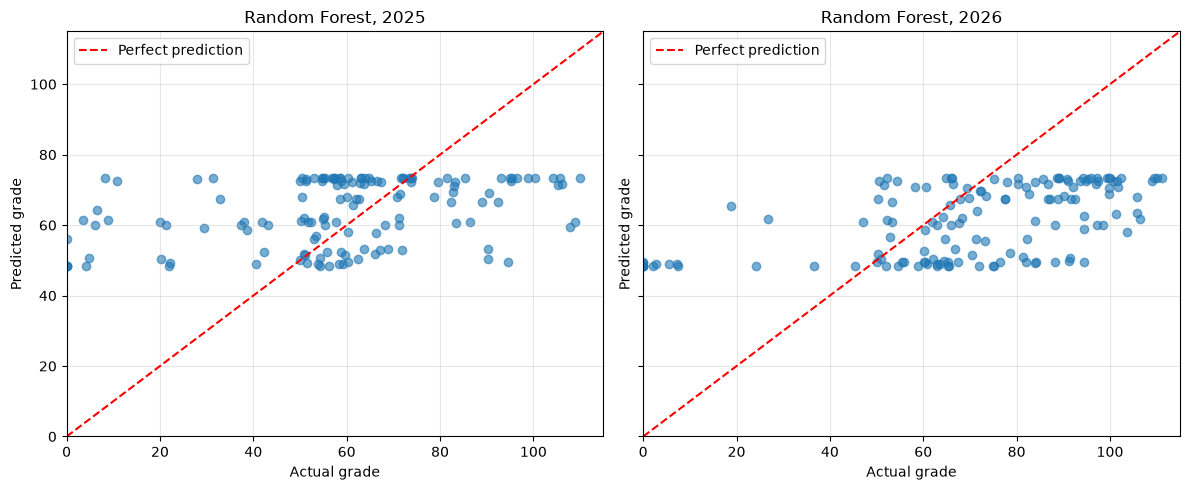

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

for ax, year, actual, predicted in [
    (axes[0], 2025, y_test_2025, pred_2025),
    (axes[1], 2026, y_test_2026, pred_2026)
]:
    ax.scatter(actual, predicted, alpha=0.6)
    ax.plot([0, 115], [0, 115], "r--", label="Perfect prediction")

    ax.set_title(f"Random Forest, {year}")
    ax.set_xlabel("Actual grade")
    ax.set_ylabel("Predicted grade")
    ax.set_xlim(0, 115)
    ax.set_ylim(0, 115)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("random_forest_predictions.png", dpi=150)
plt.show()

### Feature importance
We examine which of the four Moodle activity features contributed most to the Random Forest's predictions.

course_views           0.00
course_module_views    0.14
total_events           0.34
active_days            0.52
dtype: float64

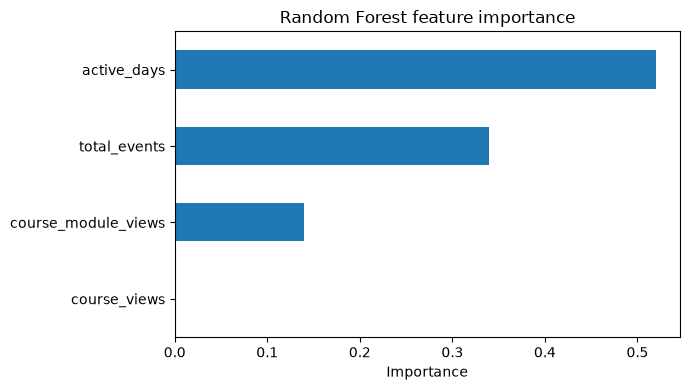

In [13]:
importance = pd.Series(
    best_forest.feature_importances_,
    index=FEATURES
).sort_values()

display(importance)

importance.plot(kind="barh", figsize=(7, 4))

plt.title("Random Forest feature importance")
plt.xlabel("Importance")
plt.tight_layout()

plt.savefig("random_forest_importance.png", dpi=150)
plt.show()


## 8. Results and conclusions

The Random Forest performed slightly better than the baseline in both test years. In 2025, the MAE was 18.78 compared to the baseline MAE of 20.21, an improvement of 1.43 grade points (7.1%). In 2026, the MAE was 20.77 compared to 21.02 for the baseline, an improvement of only 0.25 points (1.2%). This suggests that Moodle activity provides some useful information for predicting final grades, but its predictive value is limited, especially for the 2026 cohort.

The actual versus predicted grade plots show that the predictions are concentrated between approximately 50 and 75 points, while the actual grades vary much more. The model tends to overestimate low grades and underestimate high grades. This indicates that it struggles to distinguish students with very different academic results. One possible explanation is the simplicity of the selected model, which limits its ability to capture more complex relationships.

The feature importance results show that `active_days` (0.52) was the most important predictor, followed by `total_events` (0.34) and `course_module_views` (0.14). This suggests that the frequency and regularity of Moodle activity are more useful for the model than individual types of course views. The importance of `course_views` was 0, meaning that the model did not use this feature in its tree splits. However, this does not necessarily mean that course views are unrelated to academic performance.

The Random Forest also performed worse on the 2026 cohort than on the 2025 cohort. This suggests that prediction accuracy may vary across years, although the difference alone does not explain why. Changes in teaching arrangements, student behaviour or differences between cohorts could contribute to this variation.

Overall, the results show that Moodle activity alone is not sufficient for highly accurate grade prediction using the current features and model. The number of active days appears particularly informative, but students with similar Moodle activity can still achieve very different final grades. More detailed information about learning activities might improve predictions, but this would require further investigation.
